# Sorting Algorithms Performance Analysis (2)

This notebook explores and compares seven sorting algorithms: **Bubble Sort, Selection Sort, Insertion Sort, Merge Sort, Quick Sort, Heap Sort, and Hybrid Sort**.

The algorithms are implemented and tested using randomly generated datasets of different sizes. Their execution times are recorded and visualized using Matplotlib to compare their performance and understand how different sorting approaches behave as input size increases.

### Dataset Generation
Generated random integer lists of different sizes (20, 10K, 20K, 30K, 40K, and 50K) to test and compare the sorting algorithms.


In [47]:
import random
import matplotlib.pyplot as plt
import time

list20 = [random.randrange(1, 100) for foo in range(20)]
list10K = [random.randrange(1, 10000) for foo in range(10000)]
list20K = [random.randrange(1, 20000) for foo in range(20000)]
list30K = [random.randrange(1, 30000) for foo in range(30000)]
list40K = [random.randrange(1, 40000) for foo in range(40000)]
list50K = [random.randrange(1, 50000) for foo in range(50000)]

### Importing Sorting Algorithms

Imported the Bubble Sort, Selection Sort, and Insertion Sort functions from previous implementations to use them in the performance comparison and plotting process.

In [26]:
def BubbleSort(list):
    listSize = len(list)
    for i in range(0, listSize - 1):
        for j in range(0, listSize - 1):
            if list[j] > list[j + 1]:
                list[j], list[j + 1] = list[j + 1], list[j]
        listSize = listSize - 1
    return list


def SelectionSort(list):
    listSize = len(list)
    for i in range(0, listSize - 1):
        min = 10000000
        for j in range(i, listSize):
            if list[j] < min:
                min = list[j]
                minIndex = j
        list[minIndex], list[i] = list[i], list[minIndex]
    return list


def InsertionSort(list):
    listSize = len(list)
    for i in range(listSize):
        for j in range(i, 0, -1):
            if list[j] < list[j - 1]:
                list[j], list[j - 1] = list[j - 1], list[j]
    return list

### Merge Sort

Implements Merge Sort by recursively dividing the list into smaller parts and merging them back in sorted order.

- **Approach:** Divide-and-conquer, recursive sorting.
- **Time Complexity:** O(n*log(n))
- **Space Complexity:** O(n)
- **Order:** Ascending.

In [48]:
def merge(arr, left, mid, right):
    arrLeft = arr[left:mid+1]
    arrRight = arr[mid+1:right+1]
    arrFinal = []
    i = 0
    j = 0
    while i < len(arrLeft) and j < len(arrRight):
        if arrLeft[i] <= arrRight[j]:
            arrFinal.append(arrLeft[i])
            i = i + 1
        elif arrLeft[i] > arrRight[j]:
            arrFinal.append(arrRight[j])
            j = j + 1
    if i == len(arrLeft):
        for x in range(j,len(arrRight)):
            arrFinal.append(arrRight[x])
    if j == len(arrRight):
            for x in range(i,len(arrLeft)):
                arrFinal.append(arrLeft[x])
    arr[left:right+1] = arrFinal

def mergeSort(arr,left,right):
    mid = (left+right)//2
    if left >= right:
        return
    mergeSort(arr,left,mid)
    mergeSort(arr,mid+1,right)
    merge(arr,left,mid,right)

### Testing The Algorithm
l = list50K.copy()
mergeSort(l,0,len(l)-1)
print(l)

[1, 3, 3, 5, 5, 5, 5, 9, 10, 10, 11, 11, 11, 14, 15, 15, 16, 17, 17, 18, 18, 19, 20, 22, 22, 24, 25, 25, 26, 28, 28, 29, 30, 30, 33, 33, 35, 35, 36, 40, 40, 41, 42, 42, 43, 44, 45, 46, 47, 47, 47, 48, 48, 50, 53, 54, 55, 58, 58, 59, 60, 60, 60, 61, 62, 62, 63, 64, 64, 64, 64, 66, 67, 68, 68, 68, 72, 74, 74, 74, 76, 76, 77, 77, 78, 78, 81, 81, 83, 85, 86, 87, 88, 89, 90, 90, 92, 93, 93, 94, 95, 95, 96, 101, 102, 102, 104, 104, 105, 106, 107, 111, 113, 113, 115, 116, 117, 117, 117, 117, 121, 124, 124, 126, 127, 127, 128, 130, 131, 131, 131, 133, 134, 136, 136, 138, 138, 138, 139, 140, 143, 145, 145, 146, 147, 147, 148, 148, 149, 149, 150, 151, 153, 153, 154, 154, 155, 156, 156, 156, 156, 157, 157, 158, 160, 160, 160, 160, 161, 161, 161, 162, 163, 163, 164, 165, 166, 166, 167, 167, 168, 169, 169, 169, 170, 170, 171, 172, 172, 173, 176, 177, 177, 177, 177, 177, 179, 179, 182, 183, 183, 184, 185, 189, 190, 191, 191, 191, 192, 193, 197, 198, 199, 200, 200, 200, 201, 202, 202, 204, 207, 208, 

### Quick Sort

Implements Quick Sort by selecting a random pivot, partitioning the list around it, and recursively sorting the two resulting partitions.

- **Approach:** Divide-and-conquer, in-place sorting.
- **Time Complexity:** Average O(n*log(n)), Worst O(n^2).
- **Space Complexity:** Average O(n*log(n)) due to recursion.
- **Order:** Ascending.


In [49]:
def partition(arr,left,right):
    pivot_index = random.randint(left, right)
    arr[pivot_index], arr[right] = arr[right], arr[pivot_index]
    pivot = arr[right]
    tracklow = left
    for i in range(left,right):
        if arr[i] <= pivot:
            arr[tracklow],arr[i] = arr[i],arr[tracklow]
            tracklow += 1
    arr[tracklow], arr[right] = arr[right], arr[tracklow]
    return tracklow

def QuickSort(arr,left,right):
    if left < right:
        index = partition(arr,left,right)
        QuickSort(arr,left,index-1)
        QuickSort(arr,index+1,right)

### Testing The Algorithm
l = list50K.copy()
QuickSort(l,0,len(l)-1)
print(l)

[1, 3, 3, 5, 5, 5, 5, 9, 10, 10, 11, 11, 11, 14, 15, 15, 16, 17, 17, 18, 18, 19, 20, 22, 22, 24, 25, 25, 26, 28, 28, 29, 30, 30, 33, 33, 35, 35, 36, 40, 40, 41, 42, 42, 43, 44, 45, 46, 47, 47, 47, 48, 48, 50, 53, 54, 55, 58, 58, 59, 60, 60, 60, 61, 62, 62, 63, 64, 64, 64, 64, 66, 67, 68, 68, 68, 72, 74, 74, 74, 76, 76, 77, 77, 78, 78, 81, 81, 83, 85, 86, 87, 88, 89, 90, 90, 92, 93, 93, 94, 95, 95, 96, 101, 102, 102, 104, 104, 105, 106, 107, 111, 113, 113, 115, 116, 117, 117, 117, 117, 121, 124, 124, 126, 127, 127, 128, 130, 131, 131, 131, 133, 134, 136, 136, 138, 138, 138, 139, 140, 143, 145, 145, 146, 147, 147, 148, 148, 149, 149, 150, 151, 153, 153, 154, 154, 155, 156, 156, 156, 156, 157, 157, 158, 160, 160, 160, 160, 161, 161, 161, 162, 163, 163, 164, 165, 166, 166, 167, 167, 168, 169, 169, 169, 170, 170, 171, 172, 172, 173, 176, 177, 177, 177, 177, 177, 179, 179, 182, 183, 183, 184, 185, 189, 190, 191, 191, 191, 192, 193, 197, 198, 199, 200, 200, 200, 201, 202, 202, 204, 207, 208, 

## Heap Sort

Implements Heap Sort by building a Max Heap, then repeatedly moving the largest element to the end of the list and restoring the heap.

- **Approach:** Comparison-based, in-place sorting using a Max Heap.
- **Time Complexity:** O(n*log(n))
- **Space Complexity:** O(1)
- **Order:** Ascending.



In [29]:
def Heapify(arr,i,n):
    left = 2*i+1
    right = 2*i+2
    if (left < n) and (arr[left] > arr[i]):
        max = left
    else:
        max = i
    if (right < n) and (arr[right] > arr[max]):
        max = right
    if max != i:
        arr[max] , arr[i] = arr[i] , arr[max]
        Heapify(arr,max,n)

def BuildMaxHeap(arr):
    n = len(arr)
    for i in range(n//2-1,-1,-1):
        Heapify(arr,i,n)

def HeapSort(arr):
    BuildMaxHeap(arr)
    n = len(arr)
    for i in range(n-1,0,-1):
        arr[0],arr[i] = arr[i],arr[0]
        n -= 1
        Heapify(arr,0,n)

### Testing The Algorithm
l = list50K.copy()
HeapSort(l)
print(l)

[1, 1, 1, 2, 3, 4, 5, 5, 6, 8, 8, 8, 9, 11, 11, 11, 13, 13, 15, 19, 21, 21, 22, 22, 22, 23, 25, 26, 27, 27, 28, 30, 33, 34, 35, 36, 36, 38, 39, 40, 40, 41, 48, 48, 48, 50, 51, 52, 53, 58, 59, 59, 60, 62, 63, 63, 64, 65, 65, 66, 67, 68, 68, 71, 71, 78, 78, 78, 79, 80, 80, 80, 81, 81, 82, 83, 83, 84, 88, 88, 89, 90, 91, 91, 94, 95, 97, 98, 99, 103, 103, 104, 104, 104, 106, 108, 108, 111, 112, 113, 114, 115, 115, 117, 117, 117, 119, 119, 120, 126, 127, 127, 128, 128, 129, 129, 130, 132, 133, 133, 136, 137, 138, 138, 143, 144, 144, 144, 145, 150, 151, 151, 155, 159, 159, 160, 160, 163, 164, 164, 165, 167, 168, 168, 169, 170, 171, 174, 175, 175, 176, 176, 176, 178, 178, 179, 179, 180, 182, 187, 187, 189, 189, 192, 192, 194, 194, 200, 200, 200, 202, 202, 203, 204, 205, 207, 208, 209, 209, 210, 212, 212, 213, 214, 215, 215, 215, 216, 216, 217, 219, 221, 221, 223, 225, 227, 229, 229, 229, 231, 232, 233, 236, 237, 237, 237, 239, 240, 241, 243, 244, 244, 246, 248, 252, 252, 253, 255, 257, 258, 2

### Execution Time Calculation

Prepared the datasets and timing lists for all six sorting algorithms. Execution times are measured using `time.perf_counter()` and stored for comparison.

The timing calculations are commented out because the algorithms take a long time to execute. The recorded times are stored separately to allow plotting without rerunning the algorithms.

In [30]:
listNames = [list10K, list20K, list30K, list40K, list50K]
BubbleTime = []
SelTime = []
InsTime = []
MergeTime = []
QuickTime = []
HeapTime = []

# Time Calculation Commented Out 
''' DUE TO TAKING A VERY LONG TIME 
THE TIMES WERE RECORDED THEN STORED INTO A DICTIONARY TO RUN IT DIRECTLY
FEEL FREE TO COMMENT THE TIME CALCULATION OUT AND SEE THE ALGORITHM RUNNING '''

# print("InsertionSort Time Records : ")
# for i in listNames:
#     start = time.perf_counter()
#     InsertionSort(i.copy())
#     end = time.perf_counter()
#     print(f"Time : {end - start}")
#     InsTime.append({end - start})

# print("SelectionSort Time Records : ")
# for i in listNames:
#     start = time.perf_counter()
#     SelectionSort(i.copy())
#     end = time.perf_counter()
#     print(f"Time : {end - start}")
#     SelTime.append({end - start})

# print("BubbleSort Time Records : ")
# for i in listNames:
#     start = time.perf_counter()
#     BubbleSort(i.copy())
#     end = time.perf_counter()
#     print(f"Time : {end - start}")
#     BubbleTime.append({end - start})

# print("MergeSort Time Records : ")
# for i in listNames:
#     start = time.perf_counter()
#     mergeSort(i.copy(),0,len(i)-1)
#     end = time.perf_counter()
#     print(f"Time : {end - start}")
#     MergeTime.append({end - start})

# print("QuickSort Time Records : ")
# for i in listNames:
#     start = time.perf_counter()
#     QuickSort(i.copy(),0,len(i)-1)
#     end = time.perf_counter()
#     print(f"Time : {end - start}")
#     QuickTime.append({end - start})

# print("HeapSort Time Records : ")
# for i in listNames:
#     start = time.perf_counter()
#     HeapSort(i.copy())
#     end = time.perf_counter()
#     print(f"Time : {end - start}")
#     HeapTime.append({end - start})

' DUE TO TAKING A VERY LONG TIME \nTHE TIMES WERE RECORDED THEN STORED INTO A DICTIONARY TO RUN IT DIRECTLY\nFEEL FREE TO COMMENT THE TIME CALCULATION OUT AND SEE THE ALGORITHM RUNNING '

In [ ]:
BubbleTime = {
    "List 10K": 3.7071821999998065,
    "List 20K": 14.969124100000045,
    "List 30K": 37.755682300000444,
    "List 40K": 71.42086250000011,
    "List 50K": 118.36342530000002,
}

InsTime = {
    "List 10K": 3.3864649000006466,
    "List 20K": 15.079683400000249,
    "List 30K": 32.820943000000625,
    "List 40K": 64.05277649999971,
    "List 50K": 108.19490700000006,
}

SelTime = {
    "List 10K": 1.1780572999996366,
    "List 20K": 4.772252099999605,
    "List 30K": 10.955291600000237,
    "List 40K": 19.90714829999979,
    "List 50K": 33.33322919999955,
}

MergeTime = {
    "List 10K": 0.038868900000124995,
    "List 20K": 0.06310360000043147,
    "List 30K": 0.059066400000119756,
    "List 40K": 0.0822070000003805,
    "List 50K": 0.12011739999979909,
}

QuickTime = {
    "List 10K": 0.016779599999608763,
    "List 20K": 0.023515900000347756,
    "List 30K": 0.03318779999972321,
    "List 40K": 0.04377840000051947,
    "List 50K": 0.045306300000447663,
}

HeapTime = {
    "List 10K": 0.03919580000001588,
    "List 20K": 0.04698259999986476,
    "List 30K": 0.0704451000001427,
    "List 40K": 0.10365020000062941,
    "List 50K": 0.19005310000011377,
}

### Execution Time Visualization

Plots the recorded execution times of all six sorting algorithms to compare their performance across different dataset sizes.

- **Visualization:** Line plots with markers.
- **X-axis:** Dataset sizes.
- **Y-axis:** Execution time (seconds).

['Solarize_Light2', '_classic_test_patch', '_mpl-gallery', '_mpl-gallery-nogrid', 'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight', 'ggplot', 'grayscale', 'petroff10', 'seaborn-v0_8', 'seaborn-v0_8-bright', 'seaborn-v0_8-colorblind', 'seaborn-v0_8-dark', 'seaborn-v0_8-dark-palette', 'seaborn-v0_8-darkgrid', 'seaborn-v0_8-deep', 'seaborn-v0_8-muted', 'seaborn-v0_8-notebook', 'seaborn-v0_8-paper', 'seaborn-v0_8-pastel', 'seaborn-v0_8-poster', 'seaborn-v0_8-talk', 'seaborn-v0_8-ticks', 'seaborn-v0_8-white', 'seaborn-v0_8-whitegrid', 'tableau-colorblind10']


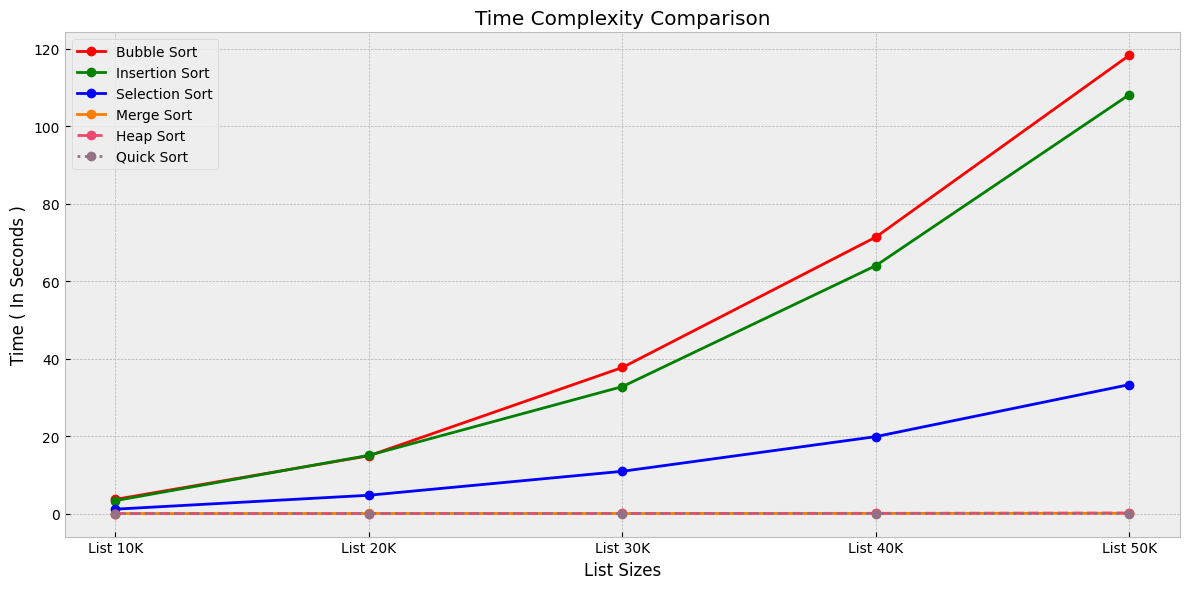

In [ ]:
plt.style.use("bmh")
plt.figure(figsize=(12, 6))
plt.plot(BubbleTime.keys(), BubbleTime.values(), marker="o", color="Red", zorder=3)
plt.plot(InsTime.keys(), InsTime.values(), marker="o", color="Green", zorder=3)
plt.plot(SelTime.keys(), SelTime.values(), marker="o", color="Blue", zorder=3)
plt.plot(MergeTime.keys(), MergeTime.values(), marker="o", color="#ff7d00", zorder=3)
plt.plot(HeapTime.keys(), HeapTime.values(), marker="o",linestyle = "--", color="#ef476f", zorder=3)
plt.plot(QuickTime.keys(), QuickTime.values(), marker="o", linestyle = ":",color="#957186", zorder=3)
plt.title("Time Complexity Comparison")
plt.ylabel("Time ( In Seconds )")
plt.xlabel("List Sizes")
plt.tight_layout()
plt.legend(labels=["Bubble Sort", "Insertion Sort", "Selection Sort","Merge Sort","Heap Sort","Quick Sort"])
plt.grid(True)
plt.show()

### Bouns Section : Hybrid Sort

Implements a Hybrid Sort by combining Merge Sort with Selection Sort. Small partitions are sorted using Selection Sort, while larger partitions are recursively divided and merged.

- **Approach:** Divide-and-conquer combined with Selection Sort.
- **Time Complexity:** O(n*log(n))
- **Space Complexity:** O(n)
- **Order:** Ascending.
- **Threshold:** 16 elements.

In [ ]:
def HybridSort(arr, left, right, threshold):
    if left >= right:
        return
    if right - left + 1 <= threshold:
        section = arr[left:right+1]
        SelectionSort(section)
        arr[left:right+1] = section
        return
    mid = (left + right) // 2
    HybridSort(arr, left, mid, threshold)
    HybridSort(arr, mid + 1, right, threshold)
    merge(arr, left, mid, right)

l = list50K.copy()
HybridSort(l, 0, len(l) - 1, 16)
print(l)

[1, 3, 3, 5, 5, 5, 5, 9, 10, 10, 11, 11, 11, 14, 15, 15, 16, 17, 17, 18, 18, 19, 20, 22, 22, 24, 25, 25, 26, 28, 28, 29, 30, 30, 33, 33, 35, 35, 36, 40, 40, 41, 42, 42, 43, 44, 45, 46, 47, 47, 47, 48, 48, 50, 53, 54, 55, 58, 58, 59, 60, 60, 60, 61, 62, 62, 63, 64, 64, 64, 64, 66, 67, 68, 68, 68, 72, 74, 74, 74, 76, 76, 77, 77, 78, 78, 81, 81, 83, 85, 86, 87, 88, 89, 90, 90, 92, 93, 93, 94, 95, 95, 96, 101, 102, 102, 104, 104, 105, 106, 107, 111, 113, 113, 115, 116, 117, 117, 117, 117, 121, 124, 124, 126, 127, 127, 128, 130, 131, 131, 131, 133, 134, 136, 136, 138, 138, 138, 139, 140, 143, 145, 145, 146, 147, 147, 148, 148, 149, 149, 150, 151, 153, 153, 154, 154, 155, 156, 156, 156, 156, 157, 157, 158, 160, 160, 160, 160, 161, 161, 161, 162, 163, 163, 164, 165, 166, 166, 167, 167, 168, 169, 169, 169, 170, 170, 171, 172, 172, 173, 176, 177, 177, 177, 177, 177, 179, 179, 182, 183, 183, 184, 185, 189, 190, 191, 191, 191, 192, 193, 197, 198, 199, 200, 200, 200, 201, 202, 202, 204, 207, 208, 